In [2]:
# STEP 1.1 — Imports, plotting defaults, load data

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.plotting import scatter_matrix
from sklearn.model_selection import train_test_split

# For regression
from sklearn.linear_model import LinearRegression

# For PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# For classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Plotting defaults
plt.style.use("dark_background")
sns.set_theme(style="darkgrid")

# Path you provided
PATH = "../../statsbomb_pipeline/data/processed/team/team_match.csv"

df = pd.read_csv(PATH)

print(df.shape)
df.head()


(760, 14)


,match_id,team_id,goals,shots,passes,carries,team_ppa,final_third_entries,team_xg,team_xthreat,team_name,opponent_id,opponent_goals,outcome
0,3753972,26,2,12,455,294,5,109,2.146323,1.466128,Swansea City,28,2,draw
1,3753972,28,2,17,577,445,14,277,1.790883,2.183882,AFC Bournemouth,26,2,draw
2,3753973,33,2,22,586,394,22,230,2.405319,1.510477,Chelsea,40,2,draw
3,3753973,40,2,13,377,262,11,129,0.886418,1.667311,West Ham United,33,2,draw
4,3753974,29,1,20,581,482,25,356,1.806268,0.562090,Everton,37,0,win


In [3]:
# STEP 1.2 — Column roles and automatic numeric detection

# Always treat these as identifiers (never as predictors)
id_cols = ["match_id", "team_id", "opponent_id"]

# Target for regression
target_reg = "team_xg"

# Potential categorical columns
categorical_cols = ["team_name", "outcome"]

# Detect numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols


['match_id',
 'team_id',
 'goals',
 'shots',
 'passes',
 'carries',
 'team_ppa',
 'final_third_entries',
 'team_xg',
 'team_xthreat',
 'opponent_id',
 'opponent_goals']

In [4]:
# STEP 1.2b — Define feature columns (predictors) for numeric modeling

base_feature_cols = [
    "goals",
    "shots",
    "passes",
    "carries",
    "team_ppa",
    "final_third_entries",
    "team_xthreat",
    "opponent_goals",
]

# Sanity: keep only those that actually exist and are numeric
base_feature_cols = [
    c for c in base_feature_cols
    if c in numeric_cols and c not in id_cols + [target_reg]
]

print("Numeric predictors:", base_feature_cols)


Numeric predictors: ['goals', 'shots', 'passes', 'carries', 'team_ppa', 'final_third_entries', 'team_xthreat', 'opponent_goals']


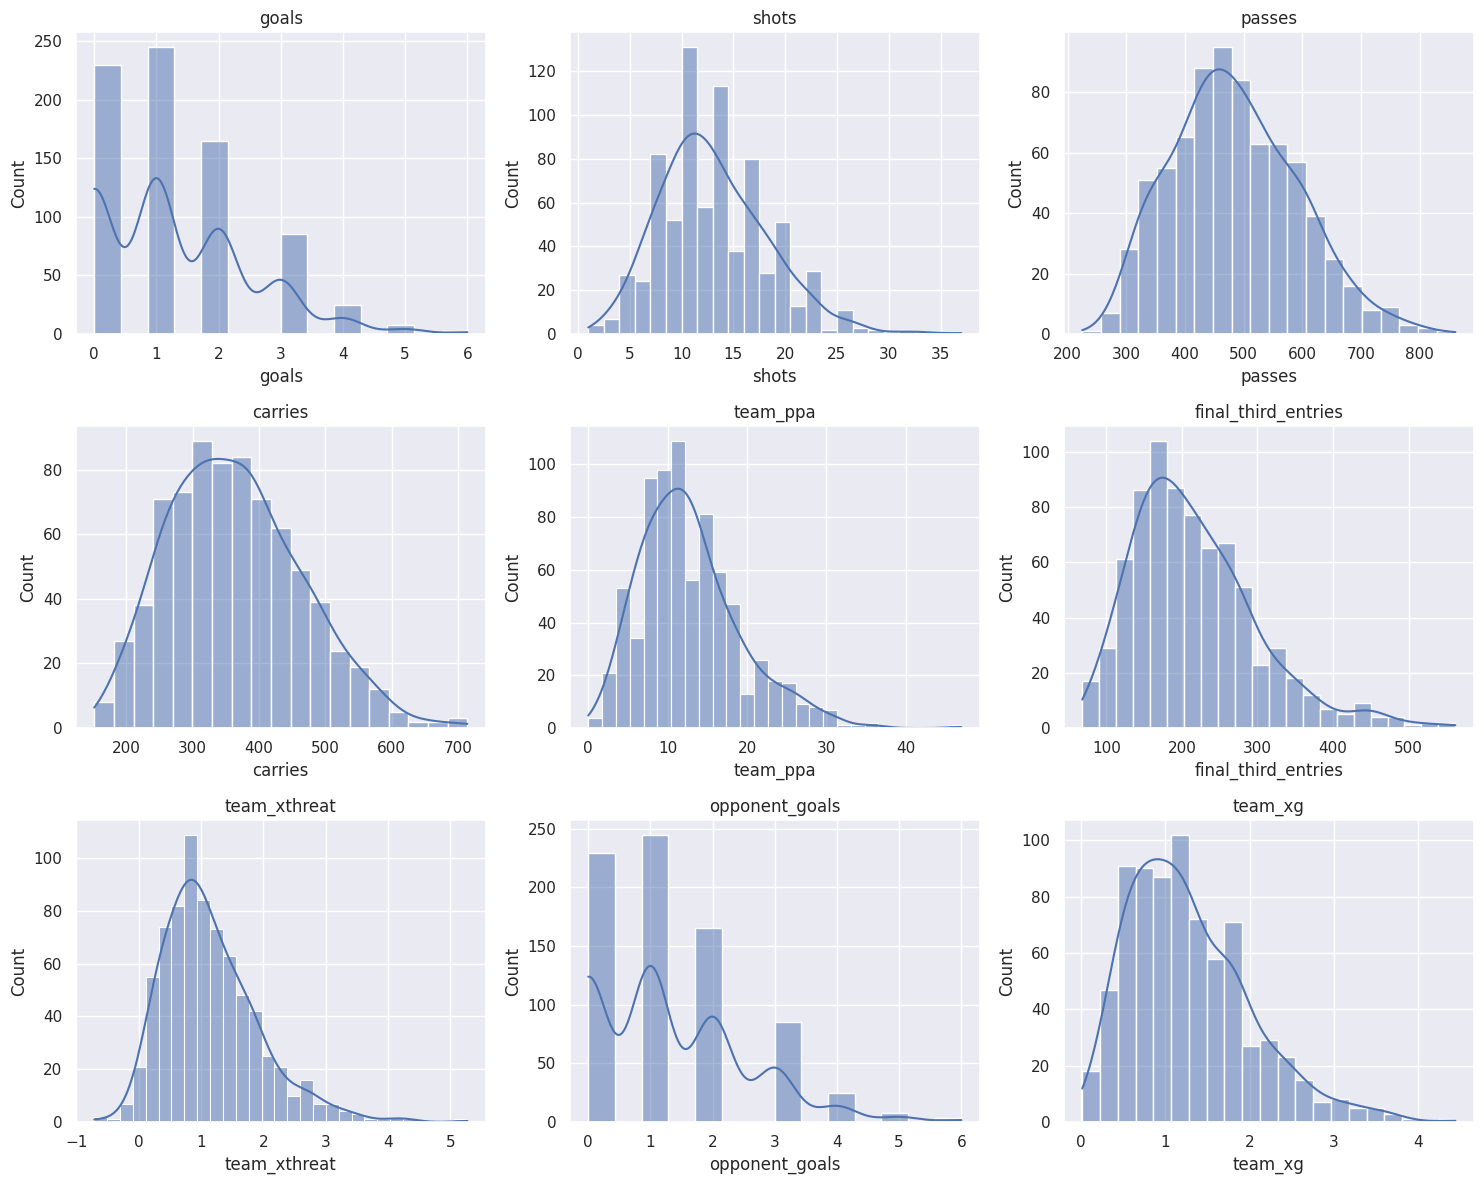

In [5]:
# STEP 1.3 — Histograms of key match metrics

key_metrics = base_feature_cols + [target_reg]

n_cols = 3
n_rows = int(np.ceil(len(key_metrics) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(key_metrics):
    ax = axes[i]
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(col)
    
# Turn off any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


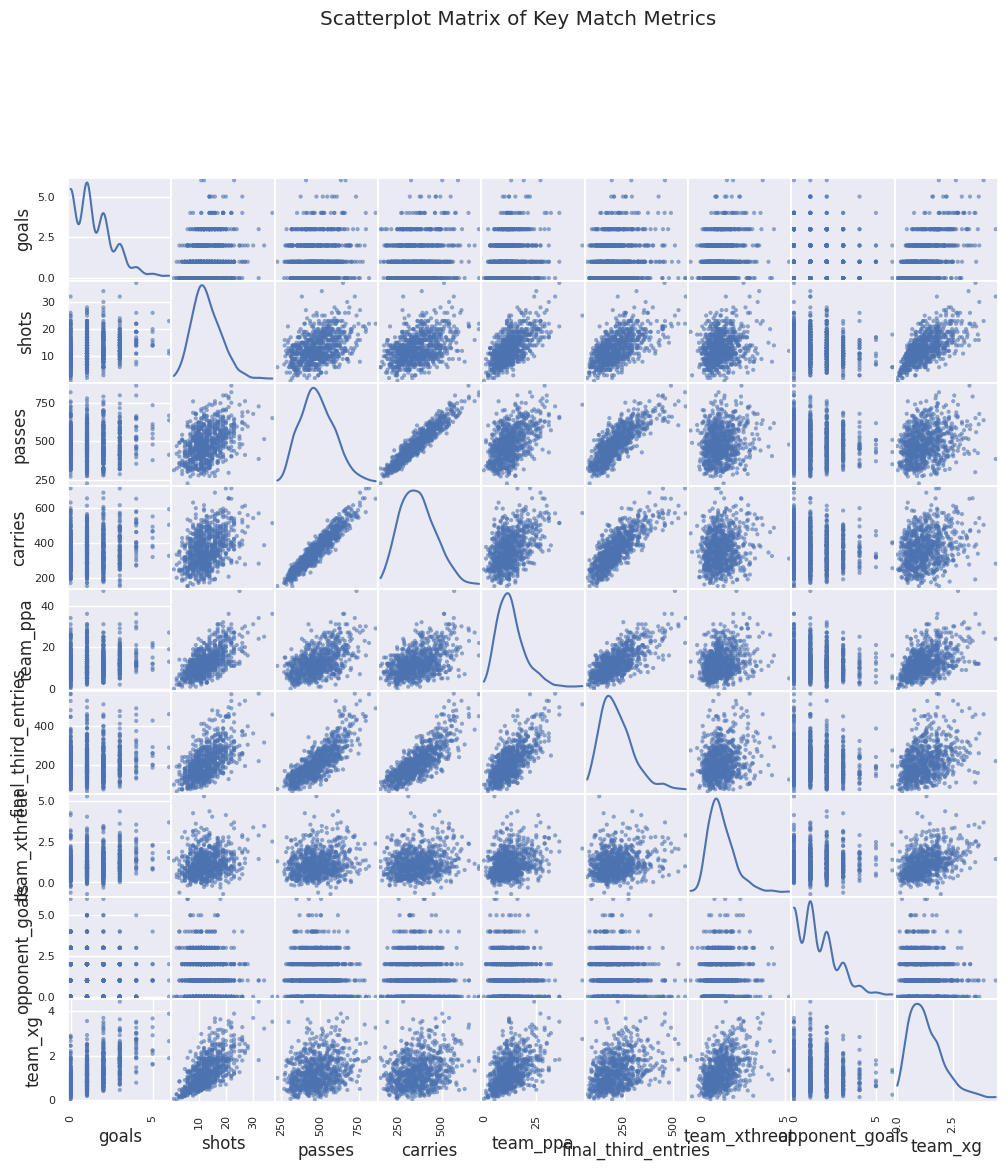

In [6]:
# STEP 1.4 — Scatterplot matrix of key metrics

pairplot_cols = key_metrics  # tweak if too many
pd.plotting.scatter_matrix(
    df[pairplot_cols],
    figsize=(12, 12),
    diagonal="kde",
    alpha=0.6
)
plt.suptitle("Scatterplot Matrix of Key Match Metrics", y=1.02)
plt.show()


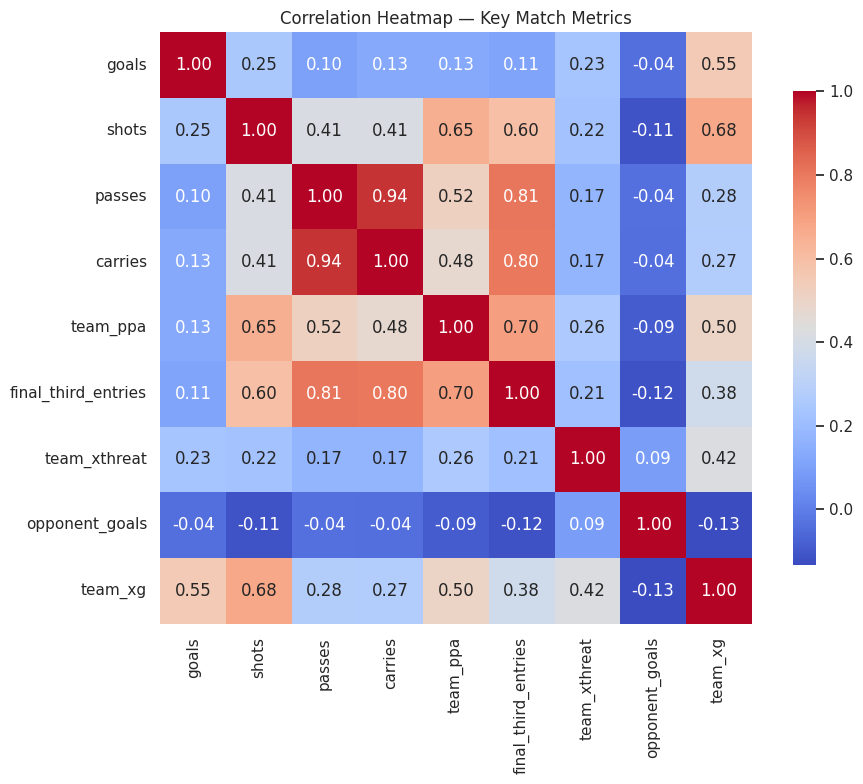

In [8]:
# STEP 1.5 — Correlation heatmap

corr = df[key_metrics].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Heatmap — Key Match Metrics")
plt.tight_layout()
plt.show()


In [9]:
# STEP 2.1 — Prepare X for PCA (numeric predictors only)

X_pca = df[base_feature_cols].dropna()  # drop rows with missing predictors
print("PCA sample size:", X_pca.shape[0])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)

# Fit PCA (keep all components)
pca = PCA()
X_pca_components = pca.fit_transform(X_scaled)

explained_var_ratio = pca.explained_variance_ratio_
eigenvalues = pca.explained_variance_

explained_var_ratio, eigenvalues


PCA sample size: 760


(array([0.46175073, 0.14952387, 0.13235545, 0.10040163, 0.0892919 ,
        0.04108492, 0.01908865, 0.00650285]),
 array([3.69887282, 1.19776695, 1.06023862, 0.80427132, 0.71527639,
        0.32911238, 0.15291041, 0.05209131]))

In [10]:
# STEP 2.2 — Explained variance and cumulative variance

pca_summary = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(explained_var_ratio))],
    "Eigenvalue": eigenvalues,
    "Explained_Variance_Ratio": explained_var_ratio,
    "Cumulative_Variance_Ratio": np.cumsum(explained_var_ratio)
})

pca_summary


,PC,Eigenvalue,Explained_Variance_Ratio,Cumulative_Variance_Ratio
0,PC1,3.698873,0.461751,0.461751
1,PC2,1.197767,0.149524,0.611275
2,PC3,1.060239,0.132355,0.743630
3,PC4,0.804271,0.100402,0.844032
4,PC5,0.715276,0.089292,0.933324
5,PC6,0.329112,0.041085,0.974409
6,PC7,0.152910,0.019089,0.993497
7,PC8,0.052091,0.006503,1.000000


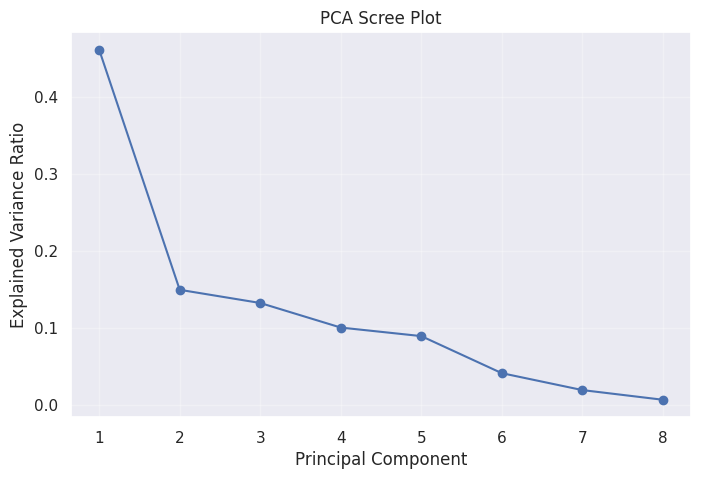

In [11]:
# Scree plot

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_var_ratio) + 1), explained_var_ratio, marker="o")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.xticks(range(1, len(explained_var_ratio) + 1))
plt.grid(True, alpha=0.3)
plt.show()


In [12]:
# STEP 2.3 — Loadings matrix

loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(len(base_feature_cols))],
    index=base_feature_cols
)

loadings


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
goals,0.128829,0.639397,-0.216908,0.626814,-0.323706,0.166803,0.039294,-0.021848
shots,0.373087,0.216901,-0.235192,-0.385209,-0.372027,-0.678255,-0.105094,-0.024100
passes,0.455475,-0.253778,0.187297,0.292478,0.104999,-0.042570,-0.335776,-0.694215
carries,0.451034,-0.240024,0.184219,0.345193,0.104772,-0.136625,-0.223995,0.711368
team_ppa,0.408320,0.085654,-0.116736,-0.460569,-0.168618,0.689569,-0.297717,0.087261
final_third_entries,0.482357,-0.143398,0.012559,-0.026133,0.006812,0.095580,0.856392,-0.057774
team_xthreat,0.174037,0.603924,0.237997,-0.178663,0.713781,-0.083206,-0.002464,-0.003394
opponent_goals,-0.060316,0.171716,0.870742,-0.096382,-0.443675,0.010224,0.049425,0.000333


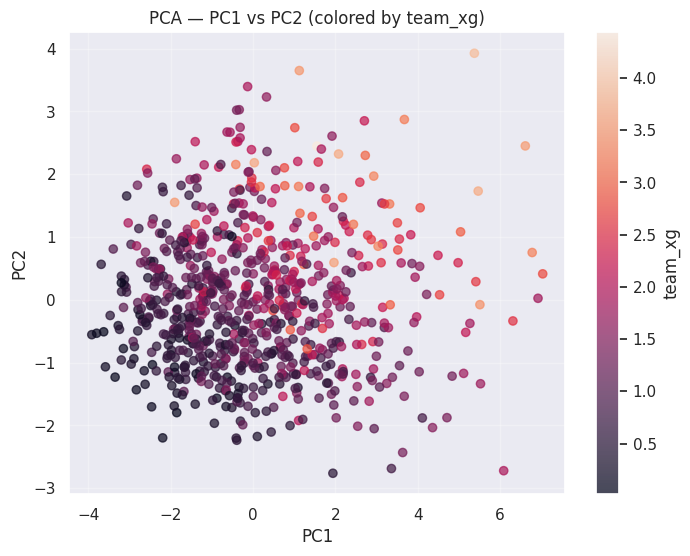

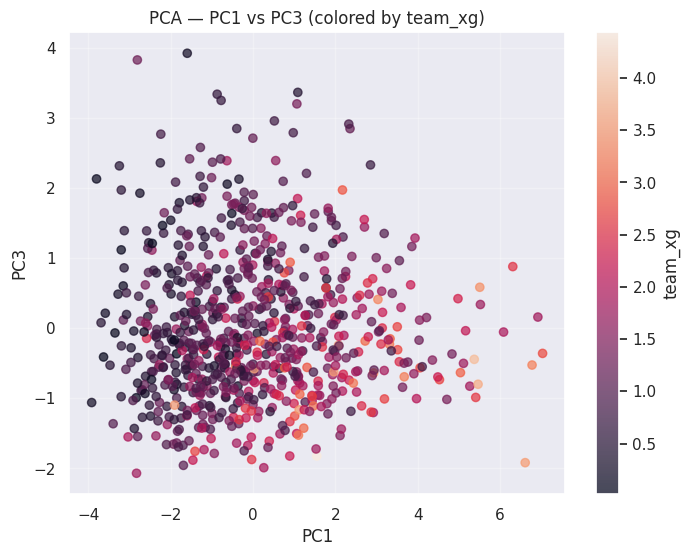

In [13]:
# STEP 2.4 — PCA scatterplots

pca_df = pd.DataFrame(
    X_pca_components,
    columns=[f"PC{i+1}" for i in range(X_pca_components.shape[1])]
)

# Optionally bring back some context (like team_xg, outcome) for coloring
pca_df["team_xg"] = df.loc[X_pca.index, target_reg]
pca_df["outcome"] = df.loc[X_pca.index, "outcome"]

# PC1 vs PC2 colored by team_xg
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    pca_df["PC1"], pca_df["PC2"],
    c=pca_df["team_xg"],
    alpha=0.7
)
plt.colorbar(scatter, label="team_xg")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA — PC1 vs PC2 (colored by team_xg)")
plt.grid(True, alpha=0.3)
plt.show()

# PC1 vs PC3 colored by team_xg
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    pca_df["PC1"], pca_df["PC3"],
    c=pca_df["team_xg"],
    alpha=0.7
)
plt.colorbar(scatter, label="team_xg")
plt.xlabel("PC1")
plt.ylabel("PC3")
plt.title("PCA — PC1 vs PC3 (colored by team_xg)")
plt.grid(True, alpha=0.3)
plt.show()


### PCA Summary and Match Archetypes (PC1–PC4, PC5)

#### 1. Variance Overview

Using eight match-level features (goals, shots, passes, carries, team_ppa, final_third_entries, team_xthreat, opponent_goals), the PCA gives:

- PC1  
  - Eigenvalue: 3.70  
  - Explained variance: 46.2%  
- PC2  
  - Eigenvalue: 1.20  
  - Explained variance: 15.0%  
- PC3  
  - Eigenvalue: 1.06  
  - Explained variance: 13.2%  
- PC4  
  - Eigenvalue: 0.80  
  - Explained variance: 10.0%  
- PC5  
  - Eigenvalue: 0.72  
  - Explained variance: 8.9%  

Cumulative variance:
- First 2 PCs explain about 61% of the variance  
- First 3 PCs explain about 74%  
- First 4 PCs explain about 84%  
- First 5 PCs explain about 93%  

PC1–PC3 carry most of the structure. PC4 and PC5 add meaningful refinements.

---

#### 2. PC1: Overall Attacking Dominance / Territory Control

**Loadings (PC1):**

- final_third_entries: 0.48  
- passes: 0.46  
- carries: 0.45  
- team_ppa: 0.41  
- shots: 0.37  
- team_xthreat: 0.17  
- goals: 0.13  
- opponent_goals: −0.06  

**Interpretation:**

- Strong positive loadings on passes, carries, final third entries, team_ppa, and shots.  
- Slightly positive on team_xthreat and goals.  
- Slightly negative on opponent_goals.

This component measures how much a team controls the game territorially and sustains pressure in advanced areas. It mixes possession, progression, box presence, and shot volume.

**Archetype:**

- High PC1:  
  - High passing and carrying volume  
  - Frequent entries into the final third  
  - Strong penalty area presence and more shots  
  - Slight tendency to limit opponent goals  
  → Attacking territorial dominance and sustained pressure

- Low PC1:  
  - Low possession and progression  
  - Few third entries and shots  
  → Passive or low-event matches

---

#### 3. PC2: Direct, Efficient End Product vs Sterile Possession

**Loadings (PC2):**

- goals: 0.64  
- team_xthreat: 0.60  
- shots: 0.22  
- opponent_goals: 0.17  
- team_ppa: 0.09  
- final_third_entries: −0.14  
- passes: −0.25  
- carries: −0.24  

**Interpretation:**

- Strong positive loadings on goals and team_xthreat.  
- Negative loadings on passes and carries.  
- Weak positive on shots and opponent_goals.

This component separates matches where the team turns limited buildup into high xThreat and goals from matches with more sterile possession and low payoff.

**Archetype:**

- High PC2:  
  - High xThreat and goal output  
  - Does not require big pass or carry volume  
  → Direct and efficient attacking, strong end product

- Low PC2:  
  - More passes and carries  
  - Lower goals and xThreat  
  → Possession heavy but blunt in the final third

In a PC1–PC2 plot:
- PC1 is how much attacking volume you generate.
- PC2 is how efficiently that volume turns into goals and xThreat.

---

#### 4. PC3: Defensive Fragility / Conceded Output

**Loadings (PC3):**

- opponent_goals: 0.87  
- team_xthreat: 0.24  
- passes: 0.19  
- carries: 0.18  
- goals: −0.22  
- shots: −0.24  
- team_ppa: −0.12  
- final_third_entries: 0.01  

**Interpretation:**

- Dominated by opponent_goals.  
- Slight positive weights on some of your possession metrics.  
- Negative on your own goals and shots.

PC3 is mainly a defensive axis. It tracks how much the team lets the opponent score, somewhat independent of its own attacking process.

**Archetype:**

- High PC3:  
  - Opponent scores many goals  
  - Your own goals and shots are relatively low  
  → Defensive collapse or high-conceding matches

- Low PC3:  
  - Opponent goals kept low  
  → Defensively solid or low-conceding matches

PC3 complements PC1 and PC2 by adding a pure defensive outcome view.

---

#### 5. PC4: Finishing Efficiency vs Wastefulness

**Loadings (PC4):**

- goals: 0.63  
- carries: 0.35  
- passes: 0.29  
- team_ppa: −0.46  
- shots: −0.39  
- team_xthreat: −0.18  
- opponent_goals: −0.10  
- final_third_entries: −0.03  

**Interpretation:**

- Positive on goals, moderate positive on passes and carries.  
- Negative on shots, team_ppa, and xThreat.

PC4 contrasts scoring output with underlying process metrics. High values suggest matches where the team scores plenty without needing huge shot volume or heavy box occupation. Low values look more like volume without conversion.

**Archetype:**

- High PC4:  
  - Fewer shots and less penalty area volume  
  - Still high goals  
  → Clinical finishing and possible overperformance versus process

- Low PC4:  
  - Many shots and strong box presence  
  - Fewer goals than expected  
  → Wasteful or underperforming finishing

PC4 is useful as a finishing efficiency lens on top of the broader volume and efficiency structure captured by PC1 and PC2.


In [14]:
# STEP 3.1 — Prepare regression dataset and split

reg_cols = base_feature_cols + [target_reg]
reg_df = df[reg_cols].dropna()

X = reg_df[base_feature_cols].values
y = reg_df[target_reg].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape


((608, 8), (152, 8))

In [15]:
# STEP 3.2 — Helper to compute regression metrics

def regression_metrics(y_true, y_pred, n_params: int):
    """
    n_params: number of predictors (p) in the model (NOT counting intercept)
    """
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    # Adj R^2, safe for small n
    if n - n_params - 1 > 0:
        adj_r2 = 1 - (1 - r2) * (n - 1) / (n - n_params - 1)
    else:
        adj_r2 = np.nan
    return r2, adj_r2, mse, rmse


In [16]:
# STEP 3.3 — Univariate regressions for every predictor

uni_results = []

for col in base_feature_cols:
    X_uni = reg_df[[col]].values
    y_uni = reg_df[target_reg].values
    
    X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(
        X_uni, y_uni, test_size=0.2, random_state=42
    )
    
    model = LinearRegression()
    model.fit(X_train_u, y_train_u)
    
    y_train_pred = model.predict(X_train_u)
    y_test_pred = model.predict(X_test_u)
    
    r2_train, adj_r2_train, mse_train, rmse_train = regression_metrics(
        y_train_u, y_train_pred, n_params=1
    )
    r2_test, adj_r2_test, mse_test, rmse_test = regression_metrics(
        y_test_u, y_test_pred, n_params=1
    )
    
    uni_results.append({
        "feature": col,
        "coef": float(model.coef_[0]),
        "intercept": float(model.intercept_),
        "r2_train": r2_train,
        "r2_test": r2_test,
        "adj_r2_train": adj_r2_train,
        "adj_r2_test": adj_r2_test,
        "mse_train": mse_train,
        "mse_test": mse_test,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test
    })

uni_results_df = pd.DataFrame(uni_results)
uni_results_df.sort_values("r2_test", ascending=False)


,feature,coef,intercept,r2_train,r2_test,adj_r2_train,adj_r2_test,mse_train,mse_test,rmse_train,rmse_test
1,shots,0.093737,0.053926,0.469298,0.387057,0.468422,0.382971,0.288350,0.275701,0.536982,0.525072
0,goals,0.330923,0.854282,0.303734,0.292609,0.302585,0.287893,0.378307,0.318184,0.615067,0.564078
4,team_ppa,0.058341,0.546338,0.261045,0.209185,0.259825,0.203913,0.401502,0.355708,0.633642,0.596412
6,team_xthreat,0.410959,0.816929,0.194519,0.098277,0.193190,0.092265,0.437647,0.405594,0.661549,0.636862
5,final_third_entries,0.003433,0.547478,0.153612,0.093608,0.152215,0.087565,0.459874,0.407694,0.678140,0.638509
2,passes,0.002003,0.319895,0.082417,0.038881,0.080903,0.032473,0.498557,0.432310,0.706085,0.657503
3,carries,0.002128,0.515830,0.082890,0.020332,0.081377,0.013800,0.498299,0.440654,0.705903,0.663817
7,opponent_goals,-0.083250,1.394053,0.019231,0.004736,0.017613,-0.001900,0.532888,0.447669,0.729992,0.669080


In [17]:
# STEP 3.4 — Multivariate models: all 2-feature and 3-feature combos

multi_results = []

def fit_and_eval_combo(feature_combo):
    X_combo = reg_df[list(feature_combo)].values
    y_combo = reg_df[target_reg].values
    
    X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
        X_combo, y_combo, test_size=0.2, random_state=42
    )
    
    model = LinearRegression()
    model.fit(X_train_c, y_train_c)
    
    y_train_pred = model.predict(X_train_c)
    y_test_pred = model.predict(X_test_c)
    
    p = len(feature_combo)
    r2_train, adj_r2_train, mse_train, rmse_train = regression_metrics(
        y_train_c, y_train_pred, n_params=p
    )
    r2_test, adj_r2_test, mse_test, rmse_test = regression_metrics(
        y_test_c, y_test_pred, n_params=p
    )
    
    return {
        "features": feature_combo,
        "r2_train": r2_train,
        "r2_test": r2_test,
        "adj_r2_train": adj_r2_train,
        "adj_r2_test": adj_r2_test,
        "mse_train": mse_train,
        "mse_test": mse_test,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test
    }

# 2-feature combos
for combo in itertools.combinations(base_feature_cols, 2):
    multi_results.append(fit_and_eval_combo(combo))

# 3-feature combos
for combo in itertools.combinations(base_feature_cols, 3):
    multi_results.append(fit_and_eval_combo(combo))

multi_results_df = pd.DataFrame(multi_results)

# Sort by test adj R^2 primarily, then test R^2
multi_results_df_sorted = multi_results_df.sort_values(
    ["adj_r2_test", "r2_test"], ascending=False
)

multi_results_df_sorted.head(10)


,features,r2_train,r2_test,adj_r2_train,adj_r2_test,mse_train,mse_test,rmse_train,rmse_test
32,"(goals, shots, team_xthreat)",0.661520,0.617589,0.659839,0.609838,0.183909,0.172008,0.428846,0.414738
30,"(goals, shots, team_ppa)",0.623689,0.599909,0.621820,0.591799,0.204464,0.179960,0.452177,0.424217
0,"(goals, shots)",0.612777,0.592418,0.611497,0.586947,0.210393,0.183330,0.458686,0.428170
33,"(goals, shots, opponent_goals)",0.615709,0.594199,0.613800,0.585973,0.208799,0.182529,0.456946,0.427234
28,"(goals, shots, passes)",0.612777,0.592418,0.610854,0.584156,0.210393,0.183330,0.458686,0.428170
29,"(goals, shots, carries)",0.613171,0.592355,0.611250,0.584092,0.210178,0.183358,0.458452,0.428203
31,"(goals, shots, final_third_entries)",0.612875,0.592316,0.610952,0.584052,0.210339,0.183376,0.458628,0.428224
44,"(goals, team_ppa, team_xthreat)",0.545834,0.480908,0.543578,0.470386,0.246765,0.233487,0.496754,0.483205
3,"(goals, team_ppa)",0.498038,0.459555,0.496379,0.452301,0.272734,0.243091,0.522240,0.493043
45,"(goals, team_ppa, opponent_goals)",0.503769,0.462104,0.501304,0.451201,0.269621,0.241945,0.519250,0.491879


In [18]:
# STEP 3.5 — Select top 3 models

top3 = multi_results_df_sorted.head(3).reset_index(drop=True)
top3


,features,r2_train,r2_test,adj_r2_train,adj_r2_test,mse_train,mse_test,rmse_train,rmse_test
0,"(goals, shots, team_xthreat)",0.661520,0.617589,0.659839,0.609838,0.183909,0.172008,0.428846,0.414738
1,"(goals, shots, team_ppa)",0.623689,0.599909,0.621820,0.591799,0.204464,0.179960,0.452177,0.424217
2,"(goals, shots)",0.612777,0.592418,0.611497,0.586947,0.210393,0.183330,0.458686,0.428170


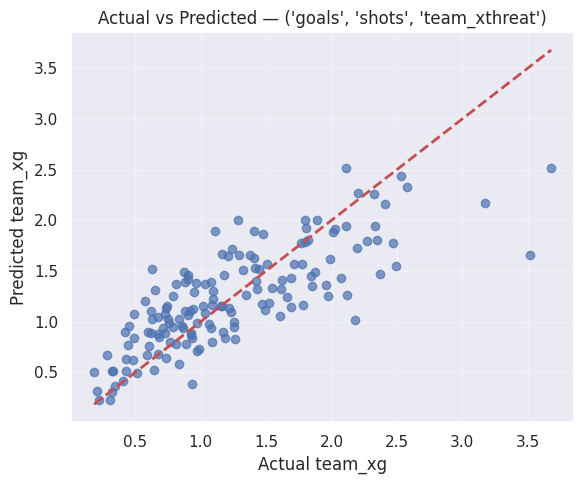

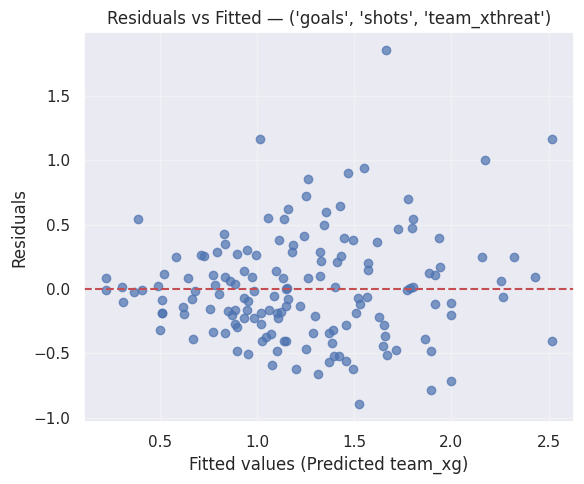

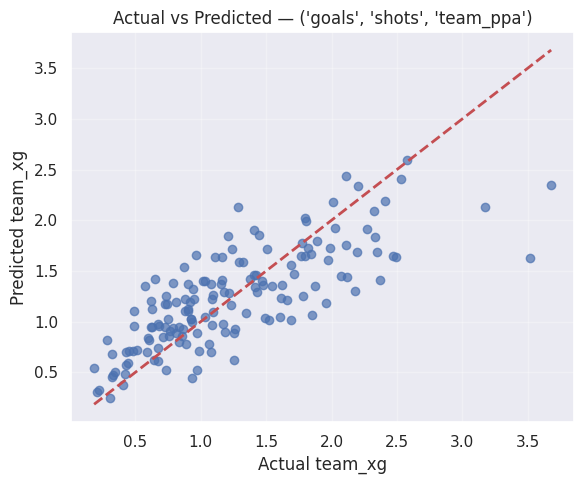

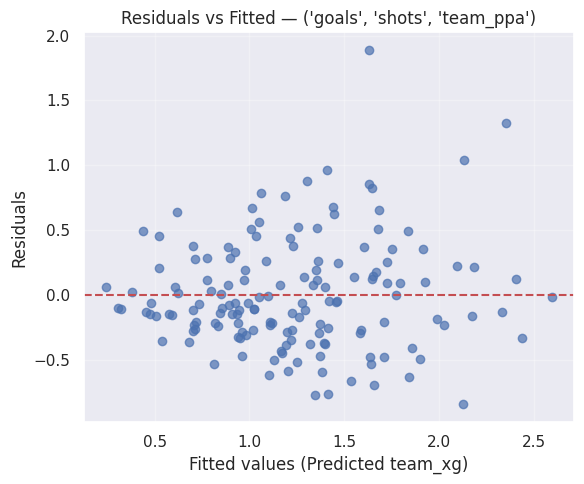

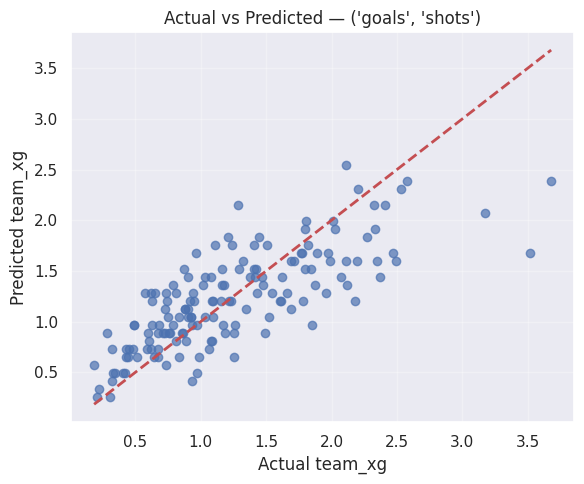

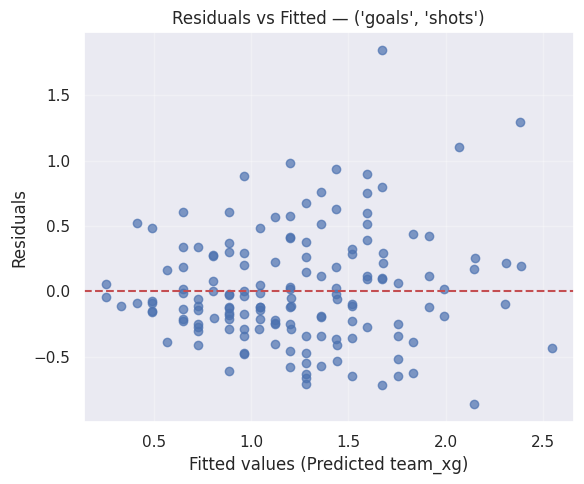

In [19]:
# STEP 3.5b — Diagnostic plots for each of the top 3 combos

def plot_diagnostics_for_combo(feature_combo):
    X_combo = reg_df[list(feature_combo)].values
    y_combo = reg_df[target_reg].values
    
    X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
        X_combo, y_combo, test_size=0.2, random_state=42
    )
    
    model = LinearRegression()
    model.fit(X_train_c, y_train_c)
    y_pred = model.predict(X_test_c)
    
    # Actual vs Predicted
    plt.figure(figsize=(6, 5))
    plt.scatter(y_test_c, y_pred, alpha=0.7)
    plt.plot([y_test_c.min(), y_test_c.max()],
             [y_test_c.min(), y_test_c.max()], "r--", linewidth=2)
    plt.xlabel("Actual team_xg")
    plt.ylabel("Predicted team_xg")
    plt.title(f"Actual vs Predicted — {feature_combo}")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    # Residuals vs Fitted
    residuals = y_test_c - y_pred
    plt.figure(figsize=(6, 5))
    plt.scatter(y_pred, residuals, alpha=0.7)
    plt.axhline(0, color="r", linestyle="--")
    plt.xlabel("Fitted values (Predicted team_xg)")
    plt.ylabel("Residuals")
    plt.title(f"Residuals vs Fitted — {feature_combo}")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

for _, row in top3.iterrows():
    combo = row["features"]
    plot_diagnostics_for_combo(combo)


In [20]:
# STEP 4.1 — Create quantile-based xG classes

class_labels = ["Low xG", "Medium xG", "High xG"]
df["xg_class"] = pd.qcut(df[target_reg], q=3, labels=class_labels)

df["xg_class"].value_counts()


xg_class
High xG      254
Low xG       253
Medium xG    253
Name: count, dtype: int64

In [21]:
# STEP 4.2 — Classification dataset

clf_target = "xg_class"   # or "outcome" if you prefer
clf_df = df[base_feature_cols + [clf_target]].dropna()

X_clf = clf_df[base_feature_cols].values
y_clf = clf_df[clf_target].values

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

X_train_clf.shape, X_test_clf.shape


((608, 8), (152, 8))

KNN Accuracy: 0.5723684210526315

KNN Classification Report:

              precision    recall  f1-score   support

     High xG       0.60      0.75      0.67        51
      Low xG       0.66      0.69      0.67        51
   Medium xG       0.39      0.28      0.33        50

    accuracy                           0.57       152
   macro avg       0.55      0.57      0.56       152
weighted avg       0.55      0.57      0.56       152



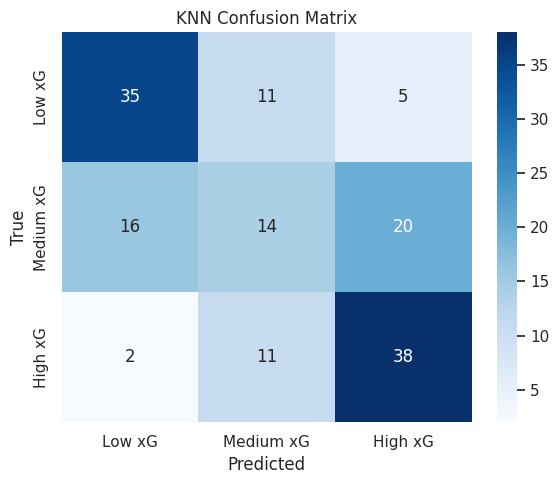

In [22]:
# STEP 4.3 — KNN classifier

from sklearn.pipeline import Pipeline

knn_k = 5  # you can tune this

knn_clf = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=knn_k))
])

knn_clf.fit(X_train_clf, y_train_clf)
y_pred_knn = knn_clf.predict(X_test_clf)

print("KNN Accuracy:", accuracy_score(y_test_clf, y_pred_knn))
print("\nKNN Classification Report:\n")
print(classification_report(y_test_clf, y_pred_knn))

cm_knn = confusion_matrix(y_test_clf, y_pred_knn, labels=class_labels)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()


Decision Tree Accuracy: 0.6118421052631579

Decision Tree Classification Report:

              precision    recall  f1-score   support

     High xG       0.67      0.71      0.69        51
      Low xG       0.74      0.63      0.68        51
   Medium xG       0.45      0.50      0.48        50

    accuracy                           0.61       152
   macro avg       0.62      0.61      0.61       152
weighted avg       0.62      0.61      0.62       152



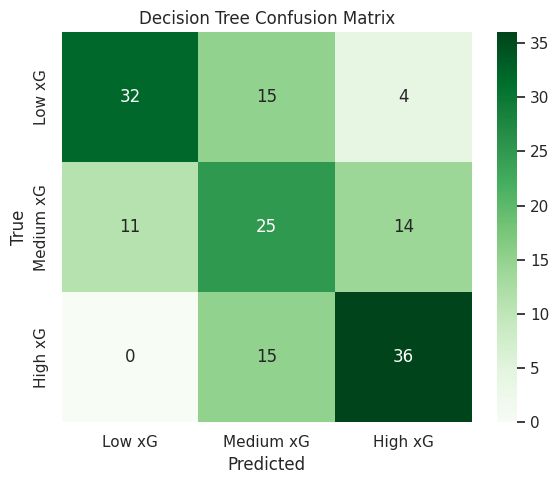

In [23]:
# STEP 4.4 — Decision Tree classifier

dt_clf = DecisionTreeClassifier(
    max_depth=4,       # tweakable
    min_samples_leaf=10,
    random_state=42
)
dt_clf.fit(X_train_clf, y_train_clf)
y_pred_dt = dt_clf.predict(X_test_clf)

print("Decision Tree Accuracy:", accuracy_score(y_test_clf, y_pred_dt))
print("\nDecision Tree Classification Report:\n")
print(classification_report(y_test_clf, y_pred_dt))

cm_dt = confusion_matrix(y_test_clf, y_pred_dt, labels=class_labels)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()
